# Load Data and Setup

In [12]:
import sys
sys.path.insert(0, "..")

from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve)


from scripts.data import fetch_raw
from scripts.split import patient_split, SEED
from scripts.preprocess import preprocess_data



In [13]:
FIGS, MODELS = Path("../reports/figures"), Path("../models")

In [14]:
FIGS, MODELS = Path("../reports/figures"), Path("../models")

df, _ = preprocess_data(fetch_raw())
X = df.drop(columns=["encounter_id", "patient_nbr", "readmitted", "readmit_30"])
y = df["readmit_30"]
train_idx, test_idx = patient_split(y, df["patient_nbr"])   # same split as 03 and 04
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

models = {
    "Logistic regression": joblib.load(MODELS / "logreg.joblib"),
    "Random forest": joblib.load(MODELS / "random_forest.joblib"),
    "XGBoost": joblib.load(MODELS / "xgboost.joblib"),
}


## Test-set metrics




In [15]:
probas = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

rows = []
for name, p in probas.items():
    pred = (p >= 0.5).astype(int)
    rows.append({"model": name,
                 "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, p),
                 "pr_auc": average_precision_score(y_test, p), "flagged": pred.mean()})
results = pd.DataFrame(rows).round(3)
results.to_csv(FIGS / "all_models_metrics.csv", index=False)
results


,model,precision,recall,f1,roc_auc,pr_auc,flagged
0,Logistic regression,0.179,0.542,0.270,0.658,0.214,0.344
1,Random forest,0.198,0.492,0.282,0.669,0.214,0.283
2,XGBoost,0.179,0.581,0.273,0.666,0.221,0.370


## ROC and PR curves




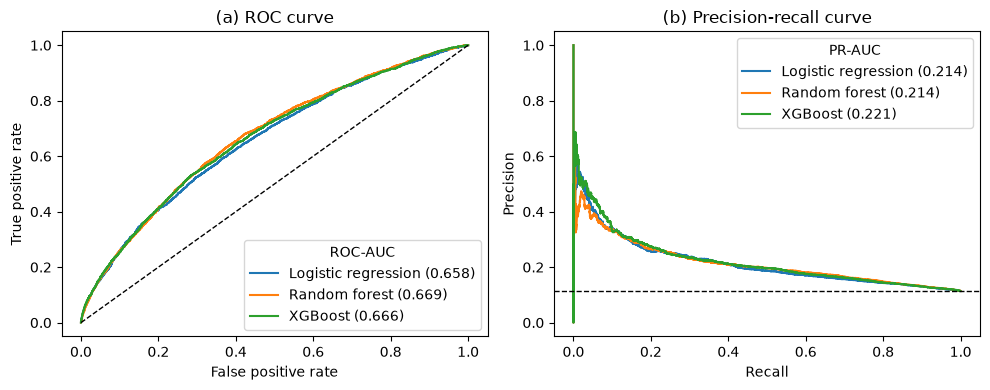

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, p):.3f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax2.axhline(y_test.mean(), color="k", ls="--", lw=1)  # random model
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="(a) ROC curve")
ax2.set(xlabel="Recall", ylabel="Precision", title="(b) Precision-recall curve")
ax1.legend(title="ROC-AUC"); ax2.legend(title="PR-AUC")
fig.tight_layout()
fig.savefig(FIGS / "all_models_curves.png", dpi=300)
plt.show()


## Same workload: top 20% flagged




In [17]:
rows = []
for name, p in probas.items():
    pred = (p >= np.quantile(p, 0.80)).astype(int)
    rows.append({"model": name, "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred)})
top20 = pd.DataFrame(rows).round(3)
top20.to_csv(FIGS / "top20_flagged.csv", index=False)
top20


,model,precision,recall
0,Logistic regression,0.216,0.380
1,Random forest,0.213,0.374
2,XGBoost,0.217,0.381


## Split check (5 seeds)

In [18]:
seed_aucs = {}
for name, model in models.items():
    aucs = []
    for seed in range(5):
        tr, te = patient_split(y, df["patient_nbr"], seed=seed)
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        aucs.append(round(roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]), 3))
    seed_aucs[name] = aucs

seed_table = pd.DataFrame(seed_aucs, index=[f"seed {s}" for s in range(5)])
seed_table.to_csv(FIGS / "seed_roc_auc.csv")
seed_table.agg(["mean", "std"]).round(3)


,Logistic regression,Random forest,XGBoost
mean,0.660,0.670,0.668
std,0.005,0.005,0.004


## Permutation importance

In [19]:
imp = {}
for name, m in models.items():
    r = permutation_importance(m, X_test, y_test, scoring="average_precision",
                               n_repeats=5, random_state=SEED, n_jobs=1)
    imp[name] = pd.Series(r.importances_mean, index=X_test.columns)
importance = pd.DataFrame(imp).sort_values("XGBoost", ascending=False).round(4)
importance.to_csv(FIGS / "permutation_importance.csv")
importance.head(10)


,Logistic regression,Random forest,XGBoost
number_inpatient,0.0618,0.0455,0.0681
discharge_disposition,0.0257,0.0356,0.0300
diag_1_group,0.0019,0.0028,0.0052
medical_specialty,0.0017,0.0046,0.0032
diag_2_group,0.0029,0.0008,0.0030
payer_code,0.0029,0.0017,0.0014
num_procedures,-0.0001,0.0004,0.0013
diag_3_group,0.0009,0.0005,0.0012
number_diagnoses,0.0015,0.0024,0.0012
time_in_hospital,0.0001,0.0018,0.0010


## Logistic regression odds ratios




In [20]:
lr = models["Logistic regression"]
coef = pd.Series(lr[-1].coef_[0], index=lr[:-1].get_feature_names_out())
odds = np.exp(coef).sort_values()
pd.concat([odds.head(8), odds.tail(8)]).round(2)


cat__payer_code_WC                                   0.48
cat__discharge_disposition_Home                      0.64
cat__payer_code_OT                                   0.64
cat__medical_specialty_Orthopedics-Reconstructive    0.69
cat__diag_3_group_Missing                            0.74
cat__discharge_disposition_Home with care            0.79
cat__medical_specialty_Cardiology                    0.83
cat__discharge_disposition_Unknown                   0.83
cat__diag_1_group_Missing                            1.30
cat__diag_3_group_Neoplasms                          1.31
cat__payer_code_Missing                              1.31
cat__diag_2_group_Neoplasms                          1.36
cat__payer_code_OG                                   1.41
num__number_inpatient                                1.44
cat__medical_specialty_Nephrology                    1.46
cat__discharge_disposition_Rehab/LTC/Psych           2.10
dtype: float64

## Insurance subgroups




In [21]:
groups = {"Medicare": X_test["medicare"].eq(1),
          "Medicaid": X_test["medicaid"].eq(1),
          "Other/missing": X_test["medicare"].eq(0) & X_test["medicaid"].eq(0)}
rows = []
for g, mask in groups.items():
    m = mask.to_numpy()
    for name, p in probas.items():
        rows.append({"group": g, "model": name, "stays": int(m.sum()),
                     "readmit_rate": y_test[m].mean(),
                     "roc_auc": roc_auc_score(y_test[m], p[m]),
                     "recall": recall_score(y_test[m], (p[m] >= 0.5).astype(int))})
subgroups = pd.DataFrame(rows).round(3)
subgroups.to_csv(FIGS / "insurance_subgroups.csv", index=False)
subgroups.pivot(index="group", columns="model", values="roc_auc")


model,Logistic regression,Random forest,XGBoost
group,,,
Medicaid,0.669,0.674,0.682
Medicare,0.642,0.656,0.656
Other/missing,0.664,0.673,0.668


In [ ]:
first = df.sort_values("encounter_id").drop_duplicates("patient_nbr")
repeat = df.drop(first.index)
print(f"First stay only: {len(first):,} stays, rate {first.readmit_30.mean():.3f}")
print(f"Repeat stays rate: {repeat.readmit_30.mean():.3f}")
print(df.groupby("a1c_tested").readmit_30.mean().round(3))
